<a href="https://colab.research.google.com/github/prajwalms07/DAV_Lab_Programs/blob/main/4NI25CS141_PrajwalMS.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Netflix Titles: Data Cleaning, Preprocessing & EDA
This notebook walks through loading, cleaning, exploring, and visualizing the Netflix titles dataset to uncover key insights.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the dataset
df = pd.read_csv('/content/netflix_titles.csv')

# Display basic information
print("Dataset Shape:", df.shape)
print("\nMissing Values Summary:")
print(df.isnull().sum())
display(df.head())

Dataset Shape: (8807, 12)

Missing Values Summary:
show_id            0
type               0
title              0
director        2634
cast             825
country          831
date_added        10
release_year       0
rating             4
duration           3
listed_in          0
description        0
dtype: int64


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


In [ ]:
# Handle missing values
df['director'] = df['director'].fillna('Unknown')
df['cast'] = df['cast'].fillna('Unknown')
df['country'] = df['country'].fillna('Unknown')

# Drop rows with critical missing values that cannot be reliably imputed
df = df.dropna(subset=['date_added', 'rating', 'duration'])

# Clean and convert date_added column
df['date_added'] = df['date_added'].str.strip()
df['date_added'] = pd.to_datetime(df['date_added'], format='%B %d, %Y', errors='coerce')

# Add release year and added year features
df['year_added'] = df['date_added'].dt.year.astype('Int64')

# Verify types and remaining nulls
print(df.info())
display(df.head())

<class 'pandas.core.frame.DataFrame'>
Index: 8790 entries, 0 to 8806
Data columns (total 13 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   show_id       8790 non-null   object        
 1   type          8790 non-null   object        
 2   title         8790 non-null   object        
 3   director      8790 non-null   object        
 4   cast          8790 non-null   object        
 5   country       8790 non-null   object        
 6   date_added    8790 non-null   datetime64[ns]
 7   release_year  8790 non-null   int64         
 8   rating        8790 non-null   object        
 9   duration      8790 non-null   object        
 10  listed_in     8790 non-null   object        
 11  description   8790 non-null   object        
 12  year_added    8790 non-null   Int64         
dtypes: Int64(1), datetime64[ns](1), int64(1), object(10)
memory usage: 970.0+ KB
None


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description,year_added
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,Unknown,United States,2021-09-25,2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm...",2021
1,s2,TV Show,Blood & Water,Unknown,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,2021-09-24,2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t...",2021
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",Unknown,2021-09-24,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...,2021
3,s4,TV Show,Jailbirds New Orleans,Unknown,Unknown,Unknown,2021-09-24,2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo...",2021
4,s5,TV Show,Kota Factory,Unknown,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,2021-09-24,2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...,2021


## Exploratory Data Analysis & Visualizations
Let's analyze the distribution of content types (Movies vs. TV Shows) and how content addition has evolved over the years.

/tmp/ipykernel_916/300186659.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='type', palette='Set2')


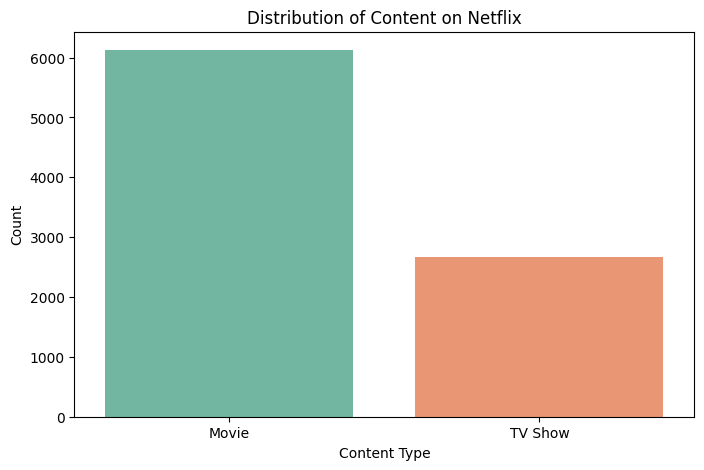

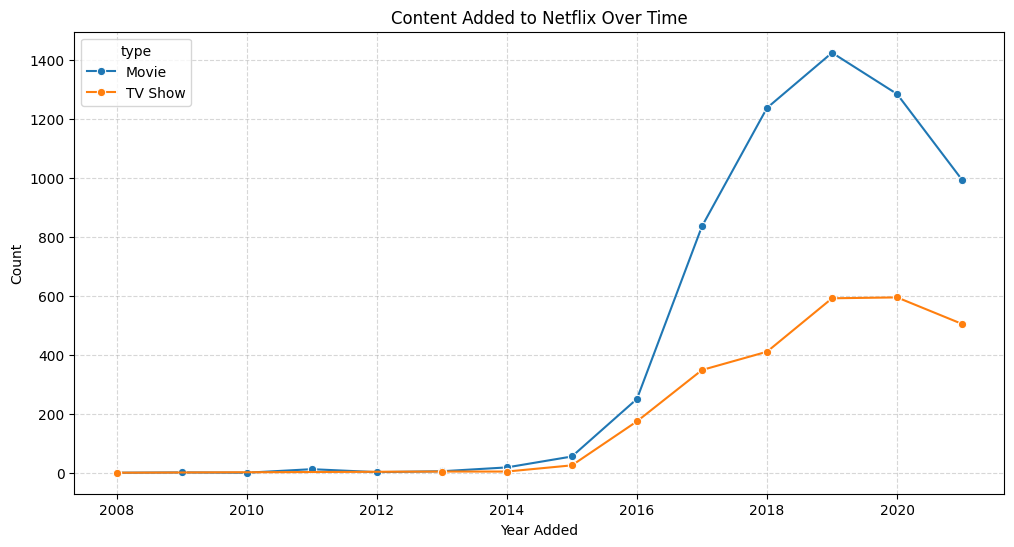

In [ ]:
# Content Type Distribution
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x='type', palette='Set2')
plt.title('Distribution of Content on Netflix')
plt.xlabel('Content Type')
plt.ylabel('Count')
plt.show()

# Content Additions Over Time
plt.figure(figsize=(12, 6))
content_by_year = df.groupby(['year_added', 'type']).size().reset_index(name='count')
sns.lineplot(data=content_by_year, x='year_added', y='count', hue='type', marker='o')
plt.title('Content Added to Netflix Over Time')
plt.xlabel('Year Added')
plt.ylabel('Count')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

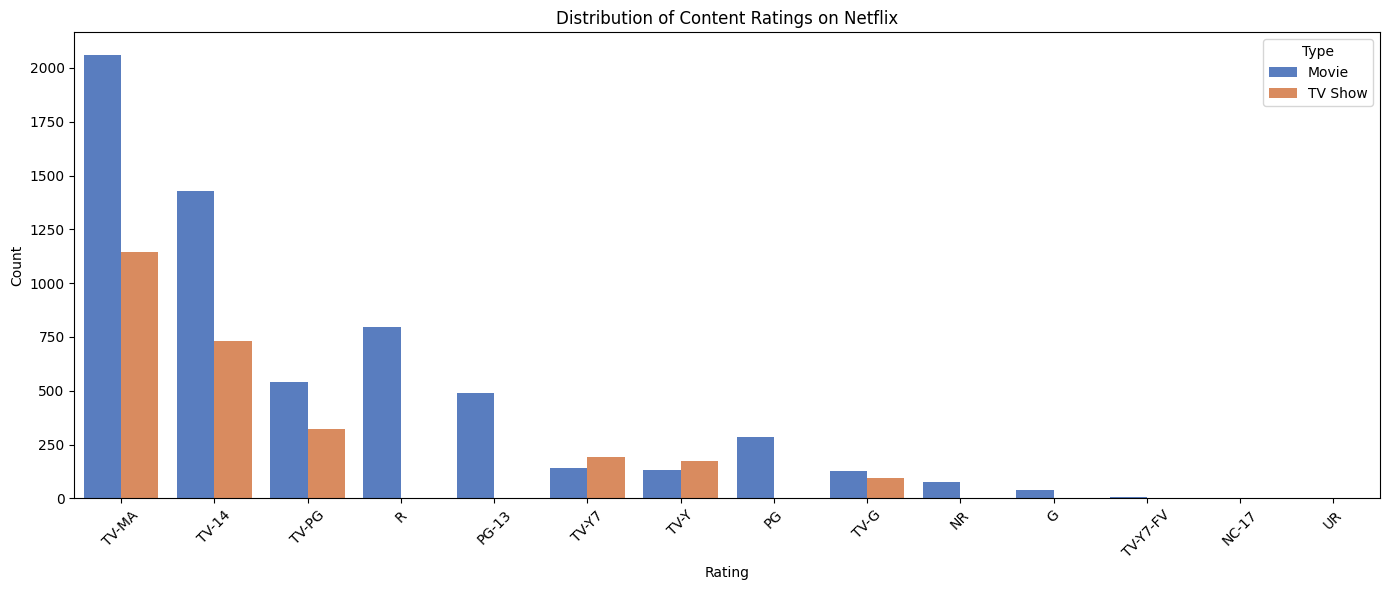

In [ ]:
# Rating distribution by type
plt.figure(figsize=(14, 6))
sns.countplot(data=df, x='rating', hue='type', order=df['rating'].value_counts().index, palette='muted')
plt.title('Distribution of Content Ratings on Netflix')
plt.xlabel('Rating')
plt.ylabel('Count')
plt.xticks(rotation=45)
plt.legend(title='Type')
plt.tight_layout()
plt.show()

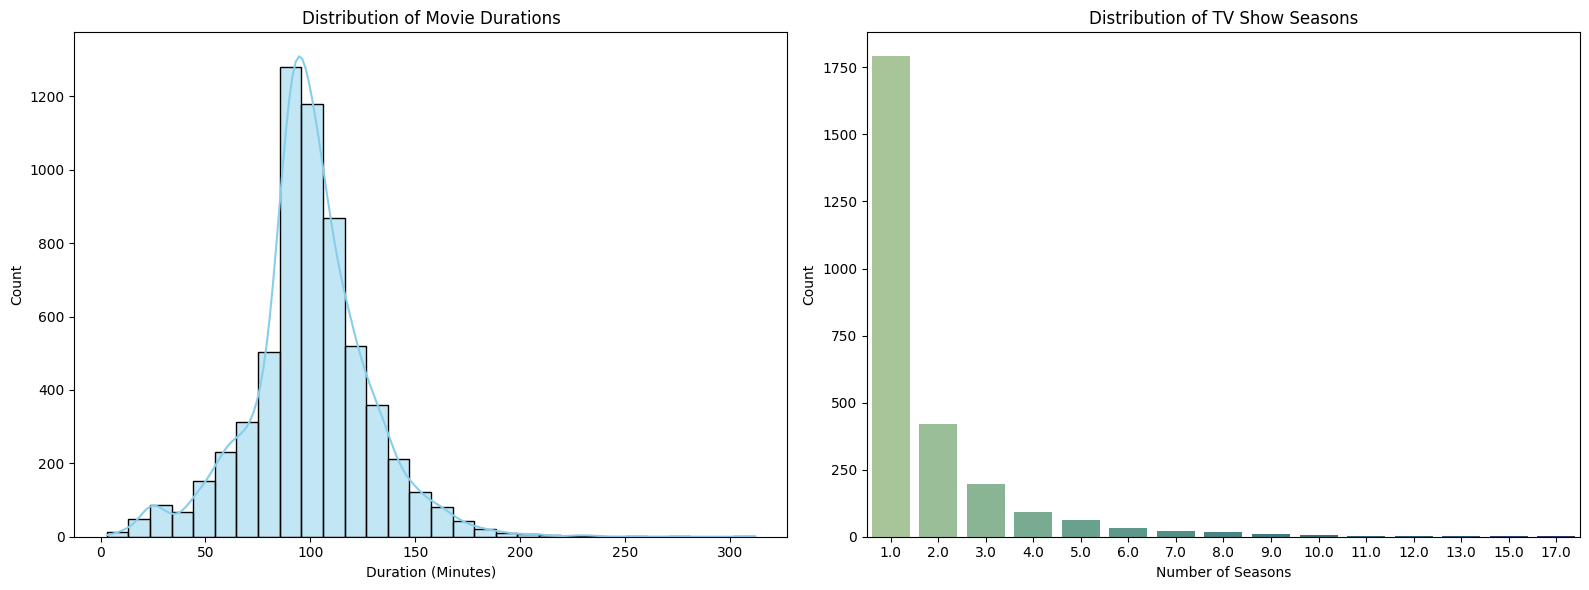

In [ ]:
# Analyze Movie and TV Show Durations separately
movies_df = df[df['type'] == 'Movie'].copy()
tv_shows_df = df[df['type'] == 'TV Show'].copy()

# Extract numeric values from duration
movies_df['duration_mins'] = movies_df['duration'].str.replace(' min', '').astype(float)
tv_shows_df['seasons'] = tv_shows_df['duration'].str.replace(' Season', '').str.replace('s', '').astype(float)

# Plot distributions
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Movie duration histogram
sns.histplot(data=movies_df, x='duration_mins', bins=30, kde=True, ax=axes[0], color='skyblue')
axes[0].set_title('Distribution of Movie Durations')
axes[0].set_xlabel('Duration (Minutes)')
axes[0].set_ylabel('Count')

# TV Show seasons barplot
sns.countplot(data=tv_shows_df, x='seasons', ax=axes[1], palette='crest', hue='seasons', legend=False)
axes[1].set_title('Distribution of TV Show Seasons')
axes[1].set_xlabel('Number of Seasons')
axes[1].set_ylabel('Count')

plt.tight_layout()
plt.show()

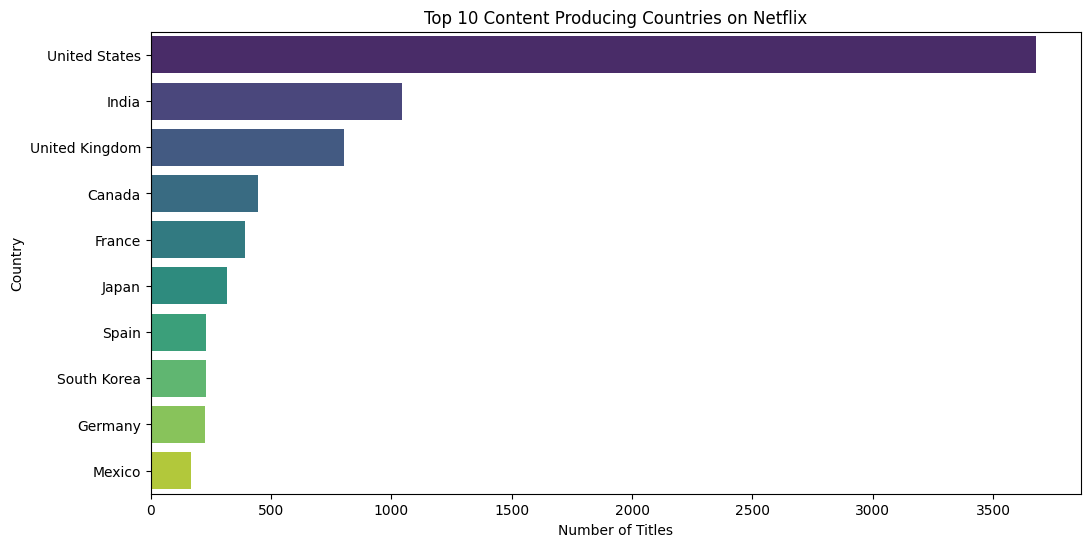

In [ ]:
# Top 10 Countries producing content
# Since country column can contain multiple comma-separated countries, we split and stack them
country_series = df['country'].str.split(', ').explode()
top_countries = country_series[country_series != 'Unknown'].value_counts().head(10)

plt.figure(figsize=(12, 6))
sns.barplot(x=top_countries.values, y=top_countries.index, palette='viridis', hue=top_countries.index, legend=False)
plt.title('Top 10 Content Producing Countries on Netflix')
plt.xlabel('Number of Titles')
plt.ylabel('Country')
plt.show()